# EDA — SMS Spam Collection

Zadanie P04. Rozkład klas, duplikaty przed i po deduplikacji, długości wiadomości i najczęstsze słowa w każdej klasie.

Statystyki zbioru liczymy na całości, ale najczęstsze słowa tylko na części treningowej (`load_split`), żeby zbiór testowy nie wpływał na żadną decyzję o modelu.

In [1]:
import sys
from pathlib import Path

# Notatnik uruchamia się z katalogu notebooks/, a moduły są w katalogu głównym repo.
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

from src.config import SEED
from src.data import load_dataset, load_split, read_raw

CLASS_NAMES = {0: "ham", 1: "spam"}
COLORS = {"ham": "#4C72B0", "spam": "#DD8452"}
pd.set_option("display.max_colwidth", 90)

## 1. Rozkład klas i duplikaty

In [2]:
raw = read_raw()
dedup = load_dataset()

counts = pd.DataFrame({
    "surowy": raw["label"].map(CLASS_NAMES).value_counts(),
    "po deduplikacji": dedup["label"].map(CLASS_NAMES).value_counts(),
}).loc[["ham", "spam"]]
counts.loc["razem"] = counts.sum()
counts["usunięte duplikaty"] = counts["surowy"] - counts["po deduplikacji"]
counts["% duplikatów"] = (100 * counts["usunięte duplikaty"] / counts["surowy"]).round(1)
counts

,surowy,po deduplikacji,usunięte duplikaty,% duplikatów
label,,,,
ham,4827,4518,309,6.4
spam,747,653,94,12.6
razem,5574,5171,403,7.2


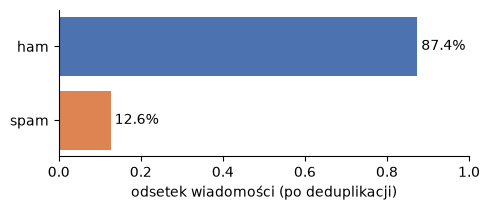

Klasyfikator większościowy (zawsze ham): accuracy = 87.4%


In [3]:
share = dedup["label"].map(CLASS_NAMES).value_counts(normalize=True).loc[["ham", "spam"]]

fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(share.index, share.values, color=[COLORS[c] for c in share.index])
for i, v in enumerate(share.values):
    ax.text(v + 0.01, i, f"{v:.1%}", va="center")
ax.set_xlim(0, 1)
ax.set_xlabel("odsetek wiadomości (po deduplikacji)")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Klasyfikator większościowy (zawsze ham): accuracy = {share['ham']:.1%}")

Zbiór jest niezbalansowany: zawsze odpowiadając „ham” dostajemy ok. 87% accuracy. Dlatego obok accuracy raportujemy F1, precision i recall dla klasy spam, a `DummyClassifier` jest grupą kontrolną (P07).

Najczęstsze duplikaty:

In [4]:
top_dups = (
    raw[raw["text"].duplicated(keep=False)]
    .groupby(["text", "label"]).size().rename("wystąpienia")
    .reset_index().sort_values("wystąpienia", ascending=False).head(8)
)
top_dups["label"] = top_dups["label"].map(CLASS_NAMES)
top_dups.reset_index(drop=True)

,text,label,wystąpienia
0,"Sorry, I'll call later",ham,30
1,I cant pick the phone right now. Pls send a message,ham,12
2,Ok...,ham,10
3,"Say this slowly.? GOD,I LOVE YOU &amp; I NEED YOU,CLEAN MY HEART WITH YOUR BLOOD.Send ...",ham,4
4,"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most ch...",ham,4
5,7 wonders in My WORLD 7th You 6th Ur style 5th Ur smile 4th Ur Personality 3rd Ur Natu...,ham,4
6,Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am...,spam,4
7,Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl charact...,ham,4


Większość usuniętych duplikatów to ham (szablonowe odpowiedzi typu „Sorry, I'll call later”), ale spam jest duplikowany proporcjonalnie dwa razy częściej (kampanie wysyłane wiele razy). Żadna treść nie ma dwóch różnych etykiet.

Co by się stało bez deduplikacji — ten sam podział 80/20 na surowym zbiorze:

In [5]:
assert raw.groupby("text")["label"].nunique().max() == 1  # brak sprzecznych etykiet

raw_train, raw_test = train_test_split(raw, test_size=0.2, stratify=raw["label"], random_state=SEED)
in_train = raw_test["text"].isin(set(raw_train["text"]))
print(f"wiadomości testowe obecne dosłownie w zbiorze treningowym: {in_train.mean():.1%}")
print(f"  w tym spam: {in_train[raw_test['label'] == 1].mean():.1%}, ham: {in_train[raw_test['label'] == 0].mean():.1%}")

wiadomości testowe obecne dosłownie w zbiorze treningowym: 12.1%
  w tym spam: 22.1%, ham: 10.6%


Bez deduplikacji co ósma wiadomość testowa (i co piąty spam) byłaby „zapamiętana” z treningu, co zawyżyłoby wyniki. Dlatego `load_dataset` usuwa duplikaty **przed** podziałem.

## 2. Długość wiadomości

In [6]:
lengths = dedup.assign(
    klasa=dedup["label"].map(CLASS_NAMES),
    znaki=dedup["text"].str.len(),
    słowa=dedup["text"].str.split().str.len(),
)
lengths.groupby("klasa")[["znaki", "słowa"]].describe().T.round(1)

klasa           ham   spam
znaki count  4518.0  653.0
      mean     70.9  137.7
      std      56.6   29.8
      min       2.0   13.0
      25%      34.0  132.0
      50%      53.0  148.0
      75%      91.0  157.0
      max     910.0  223.0
słowa count  4518.0  653.0
      mean     14.2   23.7
      std      11.2    5.9
      min       1.0    2.0
      25%       7.0   22.0
      50%      11.0   25.0
      75%      19.0   28.0
      max     171.0   35.0

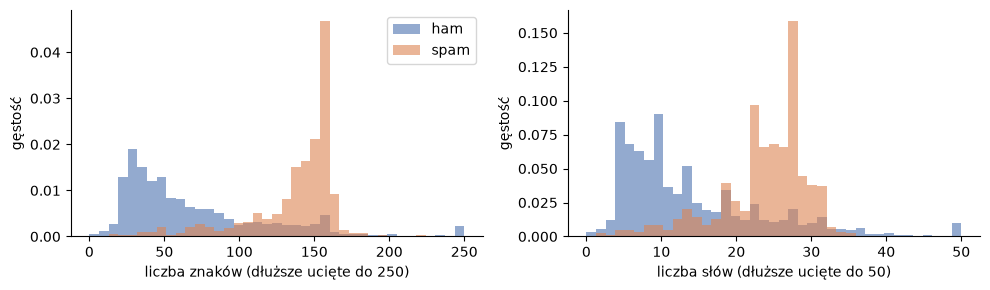

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, column, max_value, label in zip(
    axes, ["znaki", "słowa"], [250, 50], ["liczba znaków", "liczba słów"]
):
    bins = np.linspace(0, max_value, 40)
    for name in ["ham", "spam"]:
        values = lengths.loc[lengths["klasa"] == name, column].clip(upper=max_value)
        ax.hist(values, bins=bins, density=True, alpha=0.6, label=name, color=COLORS[name])
    ax.set_xlabel(f"{label} (dłuższe ucięte do {max_value})")
    ax.set_ylabel("gęstość")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend()
plt.tight_layout()
plt.show()

Spam jest wyraźnie dłuższy i bardziej jednolity: połowa spamu ma 132–157 znaków (blisko limitu 160 znaków jednego SMS-a), a ham to głównie krótkie wiadomości (mediana 53 znaki). Mediana liczby słów to 11 dla ham i 25 dla spamu, więc wektor TF-IDF ma tylko kilka–kilkanaście niezerowych pozycji. To, *które* pozycje są niezerowe, samo w sobie zdradza treść — dlatego szyfrujemy pełny wektor (atak 2 pokaże, co się dzieje bez tego).

## 3. Najczęstsze słowa w każdej klasie (tylko zbiór treningowy)

In [8]:
texts_train, _, y_train, _ = load_split()

vectorizer = CountVectorizer(stop_words="english", binary=True)
present = vectorizer.fit_transform(texts_train)
vocab = vectorizer.get_feature_names_out()
print(f"słownik (bez stop words): {len(vocab)} słów, wiadomości treningowe: {len(texts_train)}")

# Odsetek wiadomości danej klasy, w których słowo występuje.
doc_freq = pd.DataFrame({
    name: np.asarray(present[y_train == label].mean(axis=0)).ravel()
    for label, name in CLASS_NAMES.items()
}, index=vocab)

top = {name: doc_freq[name].nlargest(15) for name in ["ham", "spam"]}
pd.DataFrame({
    "ham": [f"{w} ({v:.1%})" for w, v in top["ham"].items()],
    "spam": [f"{w} ({v:.1%})" for w, v in top["spam"].items()],
})

słownik (bez stop words): 7403 słów, wiadomości treningowe: 4136


,ham,spam
0,just (6.1%),free (22.4%)
1,ok (5.6%),txt (18.6%)
2,gt (5.1%),ur (15.7%)
3,lt (5.0%),mobile (15.3%)
4,ll (4.8%),text (15.3%)
5,know (4.8%),reply (14.0%)
6,like (4.5%),stop (13.8%)
7,got (4.5%),www (13.4%)
8,good (4.5%),claim (13.2%)
9,come (4.2%),prize (10.9%)


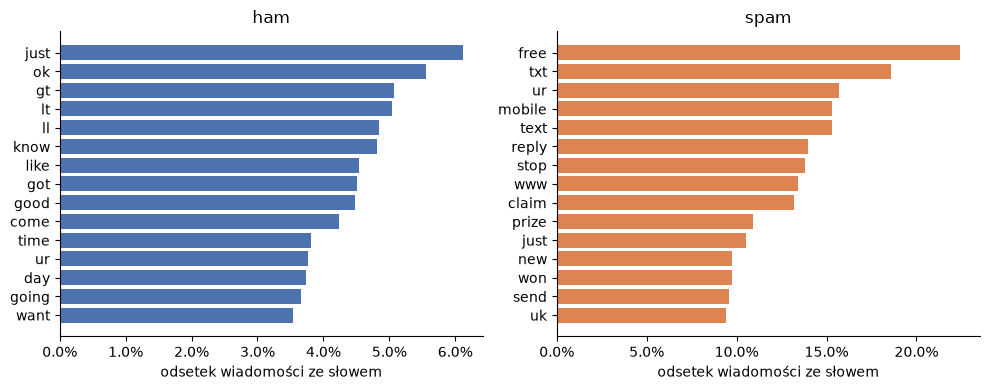

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["ham", "spam"]):
    words = top[name].iloc[::-1]
    ax.barh(words.index, words.values, color=COLORS[name])
    ax.set_title(name)
    ax.set_xlabel("odsetek wiadomości ze słowem")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Uwaga o danych: „gt” i „lt” wśród słów ham to resztki encji HTML `&lt;#&gt;`, którymi autorzy zbioru zastąpili liczby w części wiadomości (197 wiadomości po deduplikacji, wszystkie ham). Podobnie `&amp;` zamiast `&`. Nie zmieniamy tego — to cecha oryginalnego zbioru, z którym porównują się inne prace — ale warto pamiętać, że model może się na tym opierać.

In [10]:
placeholder = dedup["text"].str.contains("&lt;#&gt;", regex=False)
dedup.loc[placeholder, "label"].map(CLASS_NAMES).value_counts()

label
ham    197
Name: count, dtype: int64

Słowa najbardziej różnicujące klasy (największa różnica odsetka wiadomości, ze słów obecnych w co najmniej 1% wiadomości danej klasy):

In [11]:
frequent = doc_freq[(doc_freq["ham"] >= 0.01) | (doc_freq["spam"] >= 0.01)]
diff = (frequent["spam"] - frequent["ham"]).sort_values()
pd.DataFrame({
    "typowe dla spamu": [f"{w} (+{v:.1%})" for w, v in diff.iloc[::-1].head(12).items()],
    "typowe dla ham": [f"{w} ({v:.1%})" for w, v in diff.head(12).items()],
})

,typowe dla spamu,typowe dla ham
0,free (+21.3%),gt (-5.1%)
1,txt (+18.3%),lt (-5.0%)
2,mobile (+15.0%),ok (-4.8%)
3,text (+13.9%),ll (-4.1%)
4,www (+13.4%),come (-3.9%)
5,reply (+13.2%),got (-3.7%)
6,claim (+13.2%),lor (-3.3%)
7,stop (+13.0%),going (-3.3%)
8,ur (+11.9%),home (-3.2%)
9,prize (+10.9%),da (-2.9%)


## Wnioski dla modelu

- **Klasy 87/13** → accuracy trzeba porównywać z klasyfikatorem większościowym (ok. 87%), a jakość spamu mierzyć F1 / precision / recall. Kryterium accuracy > 94% jest więc istotnie powyżej poziomu „zgadywania”.
- **Deduplikacja przed podziałem** jest konieczna: bez niej ok. 12% wiadomości testowych (22% spamu) jest w zbiorze treningowym.
- **Spam ma silne słowa kluczowe** (free, txt, mobile, text, www, reply, claim, stop, prize, won) — model liniowy na TF-IDF (Naive Bayes) powinien wystarczyć, a selekcja chi² z k ≈ 500–1000 cech zachowa najważniejsze z nich.
- **Wiadomości są krótkie** (mediana 11 słów ham, 25 spam), więc wektory cech są bardzo rzadkie: to, *które* pozycje są niezerowe, samo w sobie zdradza treść — stąd szyfrowanie pełnego wektora.